
## Partie A : Exploration des données (EAD) et prétraitement du texte



## Préparation

In [ ]:
import re
import string
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud, STOPWORDS

import nltk
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

sns.set_theme(style="whitegrid")


#  1. Exploration et Analyse des Données (EAD)

## 1.1 Chargement des fichiers



In [ ]:
dossier = "../data/raw/"

def charger(nom):
 
    with open(dossier + nom + "_text.txt", encoding="utf-8", newline="\n") as f:
        textes = [ligne.rstrip("\r\n") for ligne in f]   
   
    with open(dossier + nom + "_labels.txt", encoding="utf-8") as f:
        labels = [int(ligne.strip()) for ligne in f]
    return pd.DataFrame({"text": textes, "label": labels})

train = charger("train")
val = charger("val")
test = charger("test")

print("train :", train.shape)
print("val   :", val.shape)
print("test  :", test.shape)

train : (2862, 2)
val   : (955, 2)
test  : (784, 2)


## 1.2 Analyse des colonnes disponibles


In [ ]:
train.head(10)

,text,label
0,seeing ppl walking w/ crutches makes me really excited for the next 3 weeks of my life,1
1,"look for the girl with the broken smile, ask her if she wants to stay while, and she will be loved. 💕🎵",0
2,Now I remember why I buy books online @user #servicewithasmile,1
3,@user @user So is he banded from wearing the clothes? #Karma,1
4,Just found out there are Etch A Sketch apps. #oldschool #notoldschool,1
5,"Hey what do you know, one of the witnesses supporting Darren Wilson's story lied! And is racist! Mind blown!",1
6,@user on stage at #flzjingleball at the @user in #Tampa #iheartradio,0
7,You know it's going to be a great day when you're Garmin resets itself and you spill some cinnamon down yourself #slowclap,1
8,Halfway thorough my workday ... Woooo,1
9,Would like to thank my nephew for giving me his horrible cold & sore throat etc.. Much appreciated!,1


In [ ]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 2862 entries, 0 to 2861
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   text    2862 non-null   str  
 1   label   2862 non-null   int64
dtypes: int64(1), str(1)
memory usage: 44.8 KB


In [ ]:
train.describe()

,label
count,2862.000000
mean,0.504892
std,0.500063
min,0.000000
25%,0.000000
50%,1.000000
75%,1.000000
max,1.000000


## 1.3 Distribution des classes (label)


In [ ]:

for nom, df in [("train", train), ("val", val), ("test", test)]:
    print(nom)
    print(df["label"].value_counts().sort_index())
    print(df["label"].value_counts(normalize=True).sort_index().round(3) * 100)
    print()

train
label
0    1417
1    1445
Name: count, dtype: int64
label
0    49.5
1    50.5
Name: proportion, dtype: float64

val
label
0    499
1    456
Name: count, dtype: int64
label
0    52.3
1    47.7
Name: proportion, dtype: float64

test
label
0    473
1    311
Name: count, dtype: int64
label
0    60.3
1    39.7
Name: proportion, dtype: float64



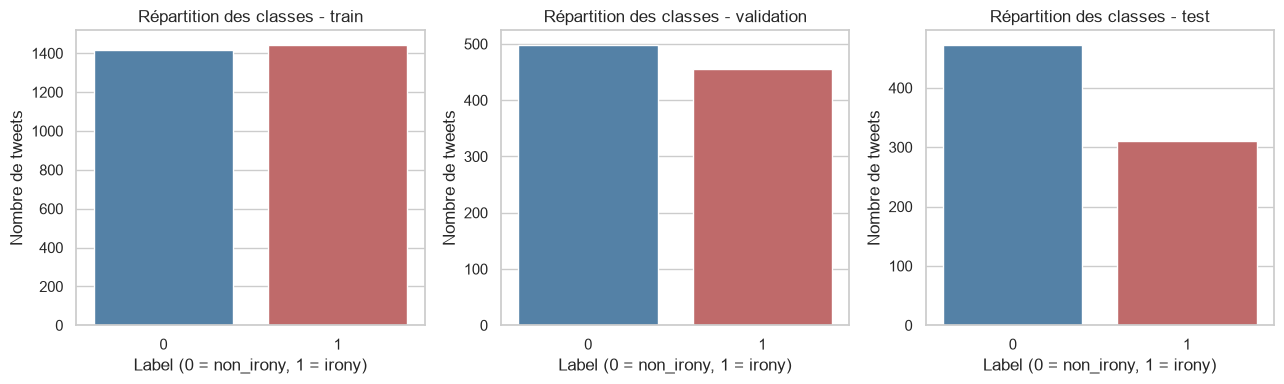

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

for ax, nom, df in zip(axes, ["train", "validation", "test"], [train, val, test]):
    sns.countplot(x="label", hue="label", data=df, ax=ax, palette=["steelblue", "indianred"], legend=False)
    ax.set_title("Répartition des classes - " + nom)
    ax.set_xlabel("Label (0 = non_irony, 1 = irony)")
    ax.set_ylabel("Nombre de tweets")

plt.tight_layout()
plt.show()

## 1.4 Longueur des textes


In [ ]:
train["n_chars"] = train["text"].str.len()
train["n_words"] = train["text"].str.split().str.len()

train[["n_chars", "n_words"]].describe()

,n_chars,n_words
count,2862.000000,2862.000000
mean,79.249476,13.605521
std,37.123625,6.694398
min,6.000000,1.000000
25%,52.000000,9.000000
50%,78.000000,13.000000
75%,106.000000,18.000000
max,1000.000000,177.000000


In [ ]:
train.groupby("label")[["n_chars", "n_words"]].mean().round(1)

,n_chars,n_words
label,,
0,80.3,13.7
1,78.2,13.5


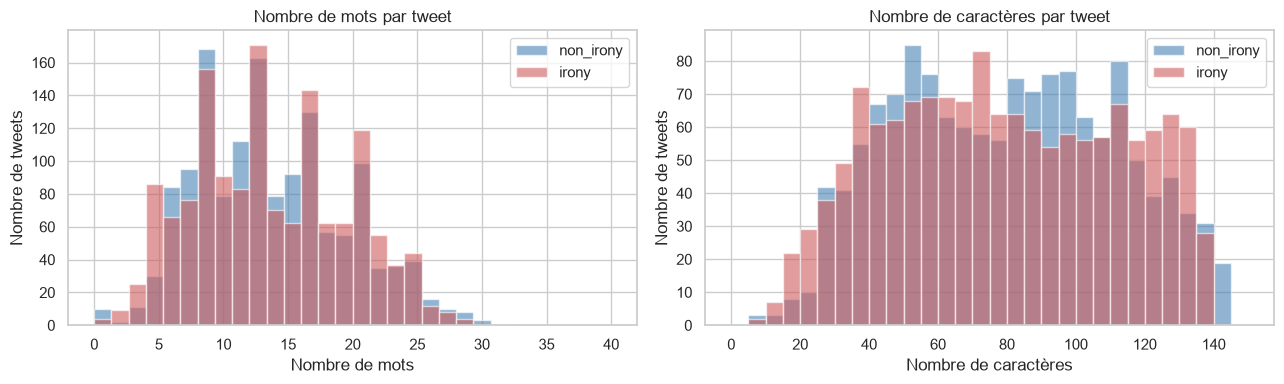

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(train[train["label"] == 0]["n_words"], bins=30, range=(0, 40), alpha=0.6, label="non_irony", color="steelblue")
axes[0].hist(train[train["label"] == 1]["n_words"], bins=30, range=(0, 40), alpha=0.6, label="irony", color="indianred")
axes[0].set_title("Nombre de mots par tweet")
axes[0].set_xlabel("Nombre de mots")
axes[0].set_ylabel("Nombre de tweets")
axes[0].legend()

axes[1].hist(train[train["label"] == 0]["n_chars"], bins=30, range=(0, 150), alpha=0.6, label="non_irony", color="steelblue")
axes[1].hist(train[train["label"] == 1]["n_chars"], bins=30, range=(0, 150), alpha=0.6, label="irony", color="indianred")
axes[1].set_title("Nombre de caractères par tweet")
axes[1].set_xlabel("Nombre de caractères")
axes[1].set_ylabel("Nombre de tweets")
axes[1].legend()

plt.tight_layout()
plt.show()

## 1.5 WordCloud : mots fréquents par classe


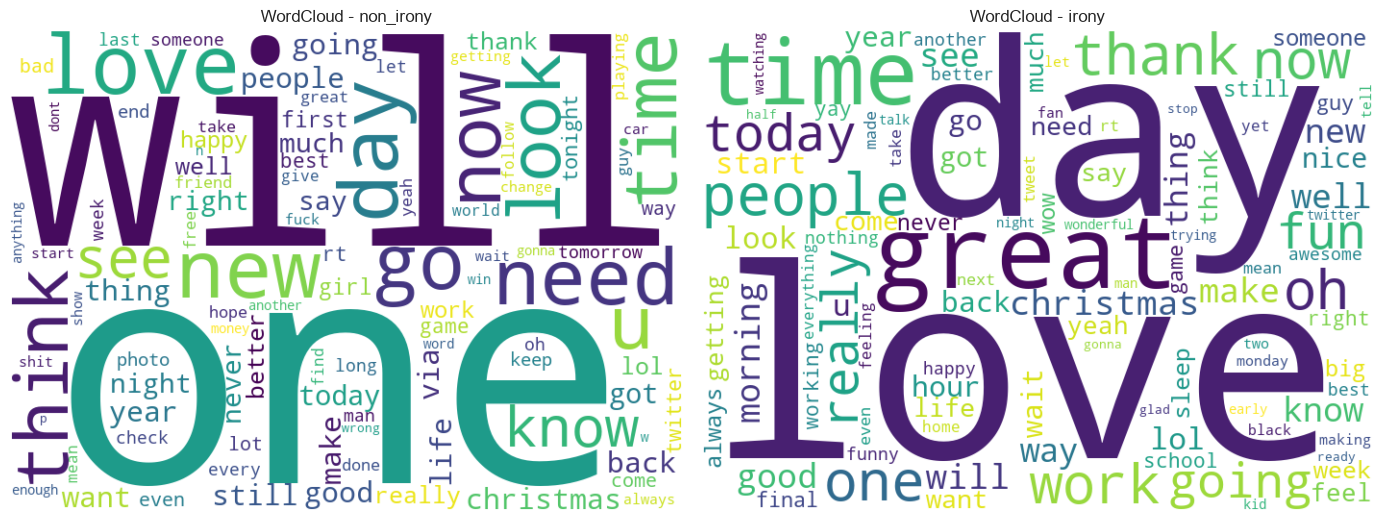

In [ ]:
a_ignorer = set(STOPWORDS) | {"user", "http", "https", "co", "amp"}

def texte_pour_nuage(serie):
    gros_texte = " ".join(serie).lower()
    gros_texte = re.sub(r"http\S+", " ", gros_texte)  
    gros_texte = re.sub(r"@\w+", " ", gros_texte)      
    return gros_texte

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, (lab, nom) in zip(axes, [(0, "non_irony"), (1, "irony")]):
    texte = texte_pour_nuage(train[train["label"] == lab]["text"])
    nuage = WordCloud(width=700, height=500, background_color="white",
                      stopwords=a_ignorer, max_words=100, random_state=42).generate(texte)
    ax.imshow(nuage, interpolation="bilinear")
    ax.set_title("WordCloud - " + nom)
    ax.axis("off")

plt.tight_layout()
plt.show()


# 2. Prétraitement du texte

## 2.1 Ce que contiennent les tweets


In [ ]:
pd.set_option("display.max_colwidth", 200)
train[["text", "label"]].sample(8, random_state=1)

,text,label
1140,@user One of those obvious when you see it but oh so clever ideas!! Glad you approved!,0
664,@user Ohhh I don't know about that! That sounds sooooo interesting!,1
2304,"@user I love the way that the #white males are buffoons, while the #black woman is smart and always wins #culturalmarxism",1
2423,Photo: #tea #art #abstract #color #colors #fun #how #are #you #artist #spainish #exhibit #spain,0
1380,"@user logic is an invention by the kuffar, everything makes perfect sense. () Like monkeys stoning she monkeys",1
366,"@user @user Would you have said in the 1800s, ""Why is GOP against Africans being brought here? Do any of them want to pick cotton?""",0
291,@user |do 4 fans!|http://t.co/TVgJXJy9DH|SmartPhone APP PAYS you & YOUR FANS!!|See-http://t.co/AlppO5hIe5 |Go 2:,0
1201,supaaa sweet when you have finals in the AM and ya can't sleep.,1


In [ ]:
print("Tweets avec une mention (@user) :", train["text"].str.contains("@").sum())
print("Tweets avec un lien (http)      :", train["text"].str.contains("http").sum())
print("Tweets avec un hashtag (#)      :", train["text"].str.contains("#").sum())
print("Total de tweets                 :", len(train))

Tweets avec une mention (@user) : 1167
Tweets avec un lien (http)      : 23
Tweets avec un hashtag (#)      : 1104
Total de tweets                 : 2862


## 2.2 Nos choix de nettoyage 



In [ ]:
stop_words = set(stopwords.words("english"))
print("Nombre de stopwords :", len(stop_words))

for mot in ["not", "no", "nor", "don't", "isn't", "never"]:
    print(mot, "->", mot in stop_words)

Nombre de stopwords : 198
not -> True
no -> True
nor -> True
don't -> True
isn't -> True
never -> False


In [ ]:
negations = {"no", "nor", "not", "never", "ain", "don", "didn", "doesn", "hadn", "hasn",
             "haven", "isn", "aren", "couldn", "shouldn", "wasn", "weren", "won",
             "wouldn", "mightn", "mustn", "needn", "shan"}

stop_words2 = {m for m in stop_words if m not in negations and "n't" not in m}

print("Avant :", len(stop_words), "stopwords")
print("Après :", len(stop_words2), "stopwords (négations conservées)")

Avant : 198 stopwords
Après : 158 stopwords (négations conservées)


## 2.3 La fonction de nettoyage


In [ ]:
lemmatizer = WordNetLemmatizer()

def nettoyer(texte):
    texte = texte.replace("’", "'")                  
    texte = re.sub(r"http\S+|www\.\S+", " ", texte)    
    texte = re.sub(r"@\w+", " ", texte)             
    texte = texte.replace("#", "")                   
    texte = texte.lower()                           

    mots = texte.split()

    mots = [m for m in mots if m.strip(string.punctuation) not in stop_words2]

    mots = [m.translate(str.maketrans("", "", string.punctuation)) for m in mots]
    mots = [m for m in mots if m != ""]

    mots = [lemmatizer.lemmatize(m) for m in mots]

    return " ".join(mots)

In [ ]:
# test sur un exemple
exemple = "Oh GREAT, @user my phone died right before the exam... #not http://t.co/abc I don't like it!!! 🙂"

print("Avant :", exemple)
print("Après :", nettoyer(exemple))

Avant : Oh GREAT, @user my phone died right before the exam... #not http://t.co/abc I don't like it!!! 🙂
Après : oh great phone died right exam not dont like 🙂


## 2.4 Création de la colonne `text_clean`


In [ ]:
train["text_clean"] = train["text"].apply(nettoyer)
val["text_clean"] = val["text"].apply(nettoyer)
test["text_clean"] = test["text"].apply(nettoyer)

train[["text", "text_clean", "label"]].head(10)

,text,text_clean,label
0,seeing ppl walking w/ crutches makes me really excited for the next 3 weeks of my life,seeing ppl walking w crutch make really excited next 3 week life,1
1,"look for the girl with the broken smile, ask her if she wants to stay while, and she will be loved. 💕🎵",look girl broken smile ask want stay loved 💕🎵,0
2,Now I remember why I buy books online @user #servicewithasmile,remember buy book online servicewithasmile,1
3,@user @user So is he banded from wearing the clothes? #Karma,banded wearing clothes karma,1
4,Just found out there are Etch A Sketch apps. #oldschool #notoldschool,found etch sketch apps oldschool notoldschool,1
5,"Hey what do you know, one of the witnesses supporting Darren Wilson's story lied! And is racist! Mind blown!",hey know one witness supporting darren wilson story lied racist mind blown,1
6,@user on stage at #flzjingleball at the @user in #Tampa #iheartradio,stage flzjingleball tampa iheartradio,0
7,You know it's going to be a great day when you're Garmin resets itself and you spill some cinnamon down yourself #slowclap,know going great day garmin reset spill cinnamon slowclap,1
8,Halfway thorough my workday ... Woooo,halfway thorough workday woooo,1
9,Would like to thank my nephew for giving me his horrible cold & sore throat etc.. Much appreciated!,would like thank nephew giving horrible cold sore throat etc much appreciated,1


In [ ]:
# vérification : y a-t-il des textes devenus vides après nettoyage ?
for nom, df in [("train", train), ("val", val), ("test", test)]:
    print(nom, ":", (df["text_clean"].str.strip() == "").sum(), "texte(s) vide(s)")

train : 1 texte(s) vide(s)
val : 2 texte(s) vide(s)
test : 0 texte(s) vide(s)


In [ ]:
# longueur moyenne avant / après nettoyage (en mots)
print("Avant :", train["text"].str.split().str.len().mean().round(1), "mots en moyenne")
print("Après :", train["text_clean"].str.split().str.len().mean().round(1), "mots en moyenne")

Avant : 13.6 mots en moyenne
Après : 7.7 mots en moyenne


# 2.5 Sauvegarde des fichiers nettoyés


In [ ]:
dossier_sortie = "../data/processed/"

train[["text", "text_clean", "label"]].to_csv(dossier_sortie + "train.csv", index=False)
val[["text", "text_clean", "label"]].to_csv(dossier_sortie + "validation.csv", index=False)
test[["text", "text_clean", "label"]].to_csv(dossier_sortie + "test.csv", index=False)

print("Fichiers sauvegardés dans", dossier_sortie)

Fichiers sauvegardés dans ../data/processed/
